<a href="https://colab.research.google.com/github/Rehan07i/pothole_detection_and_mapping/blob/main/pothole_detection_%26mapping_system_for_rainy_conditions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1 — Install YOLO
!pip -q install ultralytics

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("atulyakumar98/pothole-detection-dataset")

print("Path to dataset files:", path)


100%|██████████| 194M/194M [00:01<00:00, 140MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/atulyakumar98/pothole-detection-dataset/versions/4


In [3]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files[:10]:
        print(f"{indent}  {file}")

4/
  normal/
    210.jpg
    78.jpg
    89.jpg
    169.jpg
    256.jpg
    224.jpg
    343.jpg
    49.jpg
    176.jpg
    5.jpg
  potholes/
    210.jpg
    78.jpg
    89.jpg
    169.jpg
    256.jpg
    224.jpg
    49.jpg
    176.jpg
    5.jpg
    132.jpg


In [4]:
import glob

print("XML labels:", len(glob.glob(path + "/**/*.xml", recursive=True)))
print("YOLO TXT labels:", len(glob.glob(path + "/**/*.txt", recursive=True)))
print("CSV labels:", len(glob.glob(path + "/**/*.csv", recursive=True)))
print("JSON labels:", len(glob.glob(path + "/**/*.json", recursive=True)))

XML labels: 0
YOLO TXT labels: 0
CSV labels: 0
JSON labels: 0


In [5]:
import os
from collections import Counter

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
folders = Counter()

for root, _, files in os.walk(path):
    count = sum(file.lower().endswith(image_extensions) for file in files)
    if count:
        folders[root] = count

for folder, count in folders.most_common():
    print(f"{count:5} images  |  {folder}")

  352 images  |  /root/.cache/kagglehub/datasets/atulyakumar98/pothole-detection-dataset/versions/4/normal
  329 images  |  /root/.cache/kagglehub/datasets/atulyakumar98/pothole-detection-dataset/versions/4/potholes


In [6]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Classes:", train_ds.class_names)

Found 681 files belonging to 2 classes.
Using 545 files for training.
Found 681 files belonging to 2 classes.
Using 136 files for validation.
Classes: ['normal', 'potholes']


In [10]:
import tensorflow as tf

# ResNet50 pretrained on ImageNet
base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Keep pretrained layers fixed during initial training
base_model.trainable = False

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.12),
    tf.keras.layers.RandomBrightness(0.15),
])

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

model.save("pothole_resnet50.keras")

Epoch 1/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 16s 522ms/step - accuracy: 0.7229 - loss: 0.5293 - val_accuracy: 0.7500 - val_loss: 0.4895
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 407ms/step - accuracy: 0.7853 - loss: 0.4699 - val_accuracy: 0.8456 - val_loss: 0.4211
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 347ms/step - accuracy: 0.8367 - loss: 0.3941 - val_accuracy: 0.8824 - val_loss: 0.3673
Epoch 4/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 351ms/step - accuracy: 0.8477 - loss: 0.3720 - val_accuracy: 0.9191 - val_loss: 0.3212
Epoch 5/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 338ms/step - accuracy: 0.8514 - loss: 0.3644 - val_accuracy: 0.9191 - val_loss: 0.2844
Epoch 6/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 338ms/step - accuracy: 0.8862 - loss: 0.3229 - val_accuracy: 0.9191 - val_loss: 0.2545
Epoch 7/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 349ms/step - accuracy: 0.9064 - loss: 0.2720 - val_accuracy: 0.9338 - val_loss: 0.2313
Epoch 8/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 401ms/step - accuracy: 0.9211 - loss: 0.2418 - val_accuracy:

In [12]:
base_model.trainable = True

# Keep most pretrained layers fixed; train only the last ResNet layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

model.save("pothole_resnet50_finetuned.keras")

Epoch 1/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 493ms/step - accuracy: 0.8936 - loss: 0.3095 - val_accuracy: 0.9779 - val_loss: 0.1232
Epoch 2/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.9339 - loss: 0.2067 - val_accuracy: 0.9779 - val_loss: 0.1004
Epoch 3/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 356ms/step - accuracy: 0.9486 - loss: 0.1753 - val_accuracy: 0.9779 - val_loss: 0.0866
Epoch 4/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 349ms/step - accuracy: 0.9651 - loss: 0.1398 - val_accuracy: 0.9706 - val_loss: 0.0776
Epoch 5/5
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 354ms/step - accuracy: 0.9688 - loss: 0.1292 - val_accuracy: 0.9779 - val_loss: 0.0687


In [13]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

uploaded = files.upload()
image_name = next(iter(uploaded))

img = load_img(image_name, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)[0][0]

print("Pothole probability:", round(float(prediction) * 100, 2), "%")

if prediction >= 0.5:
    print("⚠️ Pothole detected")
else:
    print("✅ No pothole detected")

Saving images (3).jpg to images (3) (2).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Pothole probability: 95.8 %
⚠️ Pothole detected


In [16]:
!pip -q install firebase-admin

import firebase_admin
from firebase_admin import credentials, firestore
from google.colab import files

# Upload your private Firebase service-account JSON file
uploaded = files.upload()

# Get the filename of the uploaded JSON file automatically
service_account_key = next(iter(uploaded))

cred = credentials.Certificate(service_account_key)
firebase_admin.initialize_app(cred)

db = firestore.client()
print("Firebase connected using:", service_account_key)

Saving pothole-cd57b-53fe065c5a09.json to pothole-cd57b-53fe065c5a09 (1).json
Firebase connected using: pothole-cd57b-53fe065c5a09 (1).json


In [21]:
from IPython.display import Javascript, display

display(Javascript("""
window.getLocation = function() {
  return new Promise((resolve, reject) => {
    navigator.geolocation.getCurrentPosition(
      (position) => resolve({
        latitude: position.coords.latitude,
        longitude: position.coords.longitude,
        accuracy: position.coords.accuracy
      }),
      (error) => reject(error.message),
      {
        enableHighAccuracy: true,
        timeout: 10000,
        maximumAge: 5000
      }
    );
  });
};
"""))

print("GPS function is ready.")

<IPython.core.display.Javascript object>

GPS function is ready.


In [22]:
def save_pothole(latitude, longitude, accuracy, confidence):
    doc_ref = db.collection("potholes").document()
    doc_ref.set({
        "latitude": latitude,
        "longitude": longitude,
        "accuracy": accuracy,
        "confidence": confidence,
        "timestamp": firestore.SERVER_TIMESTAMP
    })

In [27]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
from google.colab.output import eval_js
import numpy as np
import urllib.request
import json

# Helper to define the JavaScript function for Geolocation in the browser
def get_gps_coordinates():
    js_code = """
    async function getLocation() {
        return new Promise((resolve, reject) => {
            navigator.geolocation.getCurrentPosition(
                (position) => {
                    resolve({
                        latitude: position.coords.latitude,
                        longitude: position.coords.longitude,
                        accuracy: position.coords.accuracy
                    });
                },
                (error) => {
                    reject(error.message);
                }
            );
        });
    }
    getLocation();
    """
    return eval_js(js_code)

# Fallback: IP-based Geolocation
def get_ip_coordinates():
    print("🛰️ Attempting IP-based geolocation fallback...")
    try:
        with urllib.request.urlopen("http://ip-api.com/json/") as response:
            data = json.loads(response.read().decode())
            if data.get("status") == "success":
                return {
                    "latitude": data.get("lat"),
                    "longitude": data.get("lon"),
                    "accuracy": 10000 # Rough estimate in meters
                }
            else:
                raise Exception("IP API responded with status: " + data.get("status", "unknown"))
    except Exception as e:
        raise Exception(f"IP geolocation failed: {e}")

# Helper to save pothole details to Firestore
def save_pothole(latitude, longitude, accuracy, confidence):
    doc_ref = db.collection("potholes").document()
    doc_ref.set({
        "latitude": latitude,
        "longitude": longitude,
        "accuracy": accuracy,
        "confidence": confidence,
        "timestamp": firestore.SERVER_TIMESTAMP
    })

uploaded = files.upload()
image_name = next(iter(uploaded))

# Prepare uploaded image for ResNet50
img = load_img(image_name, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Detect pothole
prediction = float(model.predict(img_array, verbose=0)[0][0])
print("Pothole probability:", round(prediction * 100, 2), "%")

if prediction >= 0.65:
    print("⚠️ Pothole detected. Requesting GPS location...")

    location = None
    try:
        # First, attempt browser Geolocation
        location = get_gps_coordinates()
    except Exception as e:
        print("ℹ️ Browser Geolocation blocked:", e)
        try:
            # Fallback to IP-based Geolocation
            location = get_ip_coordinates()
        except Exception as fallback_error:
            print("❌ Both Browser and IP Geolocation failed:", fallback_error)

    if location:
        save_pothole(
            latitude=location["latitude"],
            longitude=location["longitude"],
            accuracy=location["accuracy"],
            confidence=prediction
        )
        print("Latitude:", location["latitude"])
        print("Longitude:", location["longitude"])
        print("✅ Pothole report saved to Firebase.")
else:
    print("✅ No confident pothole detected; nothing saved.")

Saving images (4).jpg to images (4) (2).jpg
Pothole probability: 73.15 %
⚠️ Pothole detected. Requesting GPS location...
ℹ️ Browser Geolocation blocked: Geolocation has been disabled in this document by permissions policy.
🛰️ Attempting IP-based geolocation fallback...
Latitude: 45.5945
Longitude: -121.1786
✅ Pothole report saved to Firebase.


In [28]:
# Cell 1 — Install packages
!pip -q install ultralytics kagglehub pyyaml

In [29]:
# Cell 2 — Download YOLO-labelled pothole dataset
import kagglehub
from pathlib import Path
import yaml

dataset_path = kagglehub.dataset_download(
    "lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"
)

print("Dataset:", dataset_path)

# Find YAML configuration files
yaml_files = list(Path(dataset_path).rglob("*.yaml")) + list(Path(dataset_path).rglob("*.yml"))

for file in yaml_files:
    print(file)

Using Colab cache for faster access to the 'road-damage-dataset-potholes-cracks-and-manholes' dataset.
Dataset: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes


In [31]:
# Cell 3 — Inspect dataset structure and create a custom YOLO configuration file
import os
from pathlib import Path
import yaml

# Let's explore the directory structure to locate images and labels
print("Exploring dataset path:", dataset_path)
for root, dirs, files in os.walk(dataset_path):
    # Only print directories that actually contain files
    if files:
        level = root.replace(dataset_path, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/ contains {len(files)} files")

# Create a custom dataset configuration for YOLO
# Looking at standard setups, we define paths relative to dataset_path
config = {
    "path": dataset_path,
    "train": "train/images",
    "val": "valid/images",
    "names": {
        0: "pothole",
        1: "crack",
        2: "manhole"
    }
}

data_yaml = "dataset_config.yaml"
with open(data_yaml, "w") as file:
    yaml.dump(config, file, default_flow_style=False)

print("\nConfig file successfully created at:", os.path.abspath(data_yaml))
with open(data_yaml, "r") as file:
    print("\nCreated dataset_config.yaml content:\n", file.read())

Exploring dataset path: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes
  data/ contains 4 files
    labels/ contains 2009 files
    images/ contains 2009 files
    labels-YOLO/ contains 2009 files

Config file successfully created at: /content/dataset_config.yaml

Created dataset_config.yaml content:
 names:
  0: pothole
  1: crack
  2: manhole
path: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes
train: train/images
val: valid/images



In [5]:
# Cell 4 — Prepare split and train YOLO
import os
import shutil
from sklearn.model_selection import train_test_split
from pathlib import Path
import yaml
from ultralytics import YOLO

# Define raw dataset paths discovered in cell 3
src_img_dir = Path("/kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/images")
src_lbl_dir = Path("/kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/labels-YOLO")

# Target directory for structured YOLO training
dest_dir = Path("/content/yolo_dataset")

# Create train/val directories for YOLO
for split in ["train", "val"]:
    (dest_dir / split / "images").mkdir(parents=True, exist_ok=True)
    (dest_dir / split / "labels").mkdir(parents=True, exist_ok=True)

# Get all image files
all_images = sorted(list(src_img_dir.glob("*.jpg")) + list(src_img_dir.glob("*.png")))
image_names = [f.stem for f in all_images]

# Perform 80-20 train-test split
train_names, val_names = train_test_split(image_names, test_size=0.2, random_state=42)

# Helper function to copy files safely
def copy_split_files(names_list, split_name):
    for name in names_list:
        img_file = next(src_img_dir.glob(f"{name}.*"), None)
        lbl_file = src_lbl_dir / f"{name}.txt"

        if img_file and img_file.exists():
            shutil.copy(img_file, dest_dir / split_name / "images" / img_file.name)
        if lbl_file.exists():
            shutil.copy(lbl_file, dest_dir / split_name / "labels" / lbl_file.name)

print("Splitting and copying files...")
copy_split_files(train_names, "train")
copy_split_files(val_names, "val")
print(f"Done! Created {len(train_names)} train files and {len(val_names)} val files in {dest_dir}.")

# Create the corrected dataset YAML file pointing to the new split
yolo_config = {
    "path": str(dest_dir),
    "train": "train/images",
    "val": "val/images",
    "names": {
        0: "pothole",
        1: "crack",
        2: "manhole"
    }
}

with open("/content/dataset_config.yaml", "w") as f:
    yaml.dump(yolo_config, f, default_flow_style=False)

# Train YOLOv8 model
yolo_model = YOLO("yolov8n.pt")

yolo_model.train(
    data="/content/dataset_config.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    project="/content/runs",
    name="pothole_yolo"
)

Splitting and copying files...
Done! Created 1607 train files and 402 val files in /content/yolo_dataset.
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momen

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x797720ce39a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [8]:
# Cell 5 — Load and cleanly separate the ResNet and YOLO models
import glob
import tensorflow as tf
from ultralytics import YOLO

# 1. Load the ResNet50 classifier as 'resnet_model'
if 'model' in globals():
    resnet_model = model
    print("✅ Found 'model' in memory; assigned to 'resnet_model'")
elif glob.glob("pothole_resnet50_finetuned.keras"):
    resnet_model = tf.keras.models.load_model("pothole_resnet50_finetuned.keras")
    print("✅ Restored saved ResNet model from disk; assigned to 'resnet_model'")
else:
    print("⚠️ Could not find ResNet model in memory or disk. If you need to use it, please run the ResNet training cells first.")

# 2. Find and load the latest trained YOLO weights dynamically
runs = glob.glob("/content/runs/pothole_yolo*/weights/best.pt")
if runs:
    # Sort to get the most recent path (e.g., pothole_yolo-3)
    latest_best = sorted(runs)[-1]
    yolo_model = YOLO(latest_best)
    print(f"✅ Loaded trained YOLO detector as 'yolo_model' from: {latest_best}")
else:
    print("❌ Could not find trained YOLO weights. Please ensure Cell 4 finishes running completely first.")

✅ Restored saved ResNet model from disk; assigned to 'resnet_model'
✅ Loaded trained YOLO detector as 'yolo_model' from: /content/runs/pothole_yolo-3/weights/best.pt


Saving images (4).jpg to images (4) (4).jpg

image 1/1 /content/images (4) (4).jpg: 640x480 3 potholes, 16.9ms
Speed: 2.8ms preprocess, 16.9ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


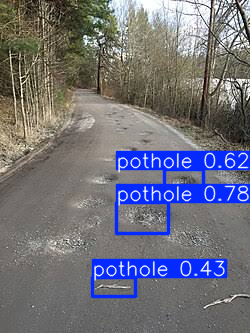

Number of detected road issues: 3


In [7]:
# Cell 6 — Upload an image and detect every pothole
from google.colab import files
from google.colab.patches import cv2_imshow
import cv2

# Gracefully check if the model is defined before proceeding
if 'yolo_model' not in globals():
    print("❌ Error: 'yolo_model' is not defined.")
    print("👉 Please ensure that YOLO training in Cell 4 finishes completely, and then run Cell 5 to load the model.")
else:
    uploaded = files.upload()
    if uploaded:
        image_name = next(iter(uploaded))

        results = yolo_model.predict(
            source=image_name,
            conf=0.30,
            save=True,
            show_labels=True,
            show_conf=True
        )

        # Display image with multiple detection boxes
        annotated_image = results[0].plot()
        cv2_imshow(annotated_image)

        print("Number of detected road issues:", len(results[0].boxes))
    else:
        print("No image was uploaded.")

In [11]:
import cv2
import numpy as np

# Load the actual image file into memory before slicing/cropping
image = cv2.imread(image_name)

yolo_results = yolo_model.predict(source=image_name, conf=0.35)

for box in yolo_results[0].boxes:
    yolo_confidence = float(box.conf[0])

    # Crop detected pothole area from the original image
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    pothole_crop = image[y1:y2, x1:x2]

    # ResNet50 verifies the cropped pothole
    crop_resized = cv2.resize(pothole_crop, (224, 224))
    crop_array = np.expand_dims(crop_resized, axis=0)
    resnet_confidence = float(resnet_model.predict(crop_array, verbose=0)[0][0])

    # Save only detections confirmed by both models
    if yolo_confidence >= 0.35 and resnet_confidence >= 0.65:
        print(f"Confirmed pothole with YOLO conf: {yolo_confidence:.2f} and ResNet conf: {resnet_confidence:.2f}")


image 1/1 /content/images (4) (4).jpg: 640x480 3 potholes, 14.5ms
Speed: 3.0ms preprocess, 14.5ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)
Confirmed pothole with YOLO conf: 0.78 and ResNet conf: 0.98
Confirmed pothole with YOLO conf: 0.62 and ResNet conf: 0.94
Confirmed pothole with YOLO conf: 0.43 and ResNet conf: 0.73


🛰️ Firestore 'db' is not defined in memory. Attempting to re-initialize automatically...
✅ Firebase successfully connected using credential file: pothole-cd57b-53fe065c5a09.json
✅ Firestore client 'db' successfully initialized!


Saving images (4).jpg to images (4) (6).jpg

image 1/1 /content/images (4) (6).jpg: 640x480 3 potholes, 18.1ms
Speed: 3.3ms preprocess, 18.1ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 480)
Confirmed potholes: 3


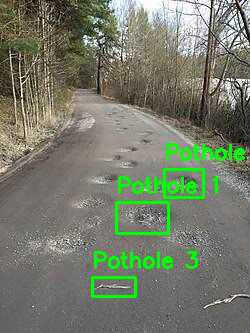

Browser GPS is unavailable in Colab: Geolocation has been disabled in this document by permissions policy.
Enter the location manually.
Latitude: 33
Longitude: 44
✅ Saved pothole: 4X6Ch3fDNf59NMAt69dd
✅ Saved pothole: Cjp9vuWxoQuyasGWisMd
✅ Saved pothole: wkGmleApTxHJckg8ygRz


In [15]:
from google.colab import files
from google.colab.output import eval_js
import firebase_admin
from firebase_admin import credentials, firestore
import cv2
import numpy as np
import glob

# Dynamic safety check to ensure Firebase/Firestore is connected
if 'db' not in globals():
    print("🛰️ Firestore 'db' is not defined in memory. Attempting to re-initialize automatically...")
    try:
        # Check if Firebase is already initialized to avoid duplicate initialization errors
        if not firebase_admin._apps:
            json_keys = glob.glob("*.json")
            # Filter out dataset or other JSONs, look for firestore key
            key_path = next((f for f in json_keys if "pothole" in f or "service" in f), None)
            if key_path:
                cred = credentials.Certificate(key_path)
                firebase_admin.initialize_app(cred)
                print(f"✅ Firebase successfully connected using credential file: {key_path}")
            else:
                raise FileNotFoundError("Could not find a Firebase credential JSON file in /content/.")
        db = firestore.client()
        print("✅ Firestore client 'db' successfully initialized!")
    except Exception as e:
        print(f"❌ Failed to automatically initialize Firestore: {e}")
        print("👉 Please run the Firebase Connection Cell (SVQgyyx4UWcI) and upload your service account key first.")

def get_gps_coordinates():
    js_code = """
    new Promise((resolve, reject) => {
        navigator.geolocation.getCurrentPosition(
            (position) => resolve({
                latitude: position.coords.latitude,
                longitude: position.coords.longitude,
                accuracy: position.coords.accuracy
            }),
            (error) => reject(error.message),
            {enableHighAccuracy: true, timeout: 10000}
        );
    });
    """
    return eval_js(js_code)

def save_pothole(latitude, longitude, accuracy, yolo_confidence,
                 resnet_confidence, bbox, image_filename):
    doc_ref = db.collection("potholes").document()
    doc_ref.set({
        "latitude": latitude,
        "longitude": longitude,
        "gpsAccuracyMeters": accuracy,
        "yoloConfidence": yolo_confidence,
        "resnetConfidence": resnet_confidence,
        "hazardClass": "pothole",
        "boundingBox": {
            "x1": bbox[0],
            "y1": bbox[1],
            "x2": bbox[2],
            "y2": bbox[3]
        },
        "imageFilename": image_filename,
        "status": "unverified",
        "timestamp": firestore.SERVER_TIMESTAMP
    })
    return doc_ref.id

# Upload road image
uploaded = files.upload()
image_name = next(iter(uploaded))

# Read original image for YOLO and ResNet crop verification
image = cv2.imread(image_name)
if image is None:
    raise ValueError("Could not read the uploaded image.")

# Find all objects with YOLO
yolo_results = yolo_model.predict(source=image_name, conf=0.35)
result = yolo_results[0]

# Get IDs of classes whose name contains 'pothole'
pothole_class_ids = [
    class_id
    for class_id, class_name in yolo_model.names.items()
    if "pothole" in class_name.lower()
]

confirmed_potholes = []

# Check each YOLO bounding box
for box in result.boxes:
    class_id = int(box.cls[0])
    yolo_confidence = float(box.conf[0])

    # Ignore cracks/manholes/other road issues if dataset contains them
    if pothole_class_ids and class_id not in pothole_class_ids:
        continue

    x1, y1, x2, y2 = map(int, box.xyxy[0])

    # Crop one detected pothole
    pothole_crop = image[y1:y2, x1:x2]
    if pothole_crop.size == 0:
        continue

    # ResNet50 was trained with RGB images, so convert OpenCV BGR to RGB
    pothole_crop_rgb = cv2.cvtColor(pothole_crop, cv2.COLOR_BGR2RGB)
    crop_resized = cv2.resize(pothole_crop_rgb, (224, 224))
    crop_array = np.expand_dims(crop_resized.astype(np.float32), axis=0)

    resnet_confidence = float(
        resnet_model.predict(crop_array, verbose=0)[0][0]
    )

    # Both models must approve the detection
    if yolo_confidence >= 0.35 and resnet_confidence >= 0.65:
        confirmed_potholes.append({
            "bbox": [x1, y1, x2, y2],
            "yoloConfidence": yolo_confidence,
            "resnetConfidence": resnet_confidence
        })

print("Confirmed potholes:", len(confirmed_potholes))

# Draw all confirmed boxes
annotated_image = image.copy()
for index, pothole in enumerate(confirmed_potholes, start=1):
    x1, y1, x2, y2 = pothole["bbox"]
    label = f"Pothole {index}"
    cv2.rectangle(annotated_image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        annotated_image, label, (x1, max(30, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
    )

from google.colab.patches import cv2_imshow
cv2_imshow(annotated_image)

# Store each confirmed pothole in Firebase
if confirmed_potholes:
    try:
        location = get_gps_coordinates()
    except Exception as error:
        print("Browser GPS is unavailable in Colab:", error)
        print("Enter the location manually.")
        location = {
            "latitude": float(input("Latitude: ")),
            "longitude": float(input("Longitude: ")),
            "accuracy": 0
        }

    for pothole in confirmed_potholes:
        document_id = save_pothole(
            latitude=location["latitude"],
            longitude=location["longitude"],
            accuracy=location["accuracy"],
            yolo_confidence=pothole["yoloConfidence"],
            resnet_confidence=pothole["resnetConfidence"],
            bbox=pothole["bbox"],
            image_filename=image_name
        )
        print("✅ Saved pothole:", document_id)
else:
    print("No potholes were confirmed by both models.")

In [16]:
# Cell 7 — Save the best trained YOLO weights to Google Drive
from google.colab import drive
import os
import glob
import shutil

drive.mount("/content/drive")

save_folder = "/content/drive/MyDrive/pothole_detector"
os.makedirs(save_folder, exist_ok=True)

# Dynamically locate the latest trained best.pt weights
runs = glob.glob("/content/runs/pothole_yolo*/weights/best.pt")
if runs:
    latest_best = sorted(runs)[-1]
    destination = os.path.join(save_folder, "pothole_yolo_best.pt")
    shutil.copy(latest_best, destination)
    print(f"✅ YOLO model successfully copied to Google Drive at: {destination}")
else:
    print("❌ No trained weights found to save.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ YOLO model successfully copied to Google Drive at: /content/drive/MyDrive/pothole_detector/pothole_yolo_best.pt
